# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Domingo, Judiele Fatima P.
- _Student No._: 2023-0167
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures
<img src="9_sine.png" alt="Synthetic Data Interpolation" > 

**Figure 1. Synthetic data interpolation.** 

<img src="9_sampling_rates.png" alt="Real world data" > 

**Figure 2. Real-world data reconstruction.** 

### Report discussion

**Interpolator comparison:** Cubic, linear, and quadratic interpolation methods show no visible undershooting and overshooting. In terms of speed, linear is most efficient; however, cubic spline and cubic interp1d are most compatible with f(x) due to its continuity in $C^2$ cubic spline is more applicable as it is slightly faster than cubic interp1d and linear interpolation may start over or undershooting values if the sample points are too far apart. Lastly, nearest-neighbor interpolation creates a discontinous step function therefore, it is not appropiate for a trigonometric function.

**Sampling-level comparison:** Reconstruction quality for high sample rates (30% and 50%) is high while for lower sampling rates degrades as sample points miss the local extrema and causes smoothing. Visible artifacts include missed extrema ($x \approx 200, y \approx 14000$ and $x \approx 550, y \approx 7500$), boundary edge distortions at $x \approx 50, x \approx 1000$, overshooting at sparse intervals, and flattening of sharp fluctuations.   

### Other comments
- N/A

---
## Section 2: Code

In [1]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy import interpolate
# from pathlib import Path

# rng = np.random.default_rng(42)
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)
rng

Generator(PCG64) at 0x7FD22D180040

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

In [2]:
x = np.linspace(-5,5,1000) #domain
def f(x) : #sine function
   return np.sin(x) 

sample_points = np.random.choice(x, size = 50, replace = False) #chooses 50 random points
y = np.array([f(point) for point in sample_points]) #evaluates corresponding sine value of all random sample points

In [3]:
import time #for timing diff interpolation methods to be used for comparison
#using different interpolation methods


#Cubic Spline
x_sorted = sample_points[np.argsort(sample_points)] #cubic spline function requires arguments to be sorted in ascending order
y_sorted = y[np.argsort(sample_points)]
x_new = np.linspace(min(x_sorted), max(x_sorted), 1000) #creates a domain from min and max sample points

start=time.time()
cs = interpolate.CubicSpline(x_sorted,y_sorted) #cubic spline function 
y_cubicspline = cs(x_new)
end=time.time()
cslength = end - start
#interp1d cubic
start=time.time()
cubic_interp1d = interpolate.interp1d(x_sorted,y_sorted, kind='cubic') #cubic interp1d function
y_interp1d = cubic_interp1d(x_new)
end=time.time()
interp1dlength = end-start

#interp1d linear
start=time.time()
linear_interp1d = interpolate.interp1d(x_sorted,y_sorted, kind='linear') #linear interp1d function
y_interp1d2 = linear_interp1d(x_new)
end = time.time()
interp1dlength2 = end-start

#interp1d nearest
start=time.time()
nearest_interp1d = interpolate.interp1d(x_sorted,y_sorted, kind='nearest') #nearest neighbo interp1d function
y_interp1d3 = nearest_interp1d(x_new)
end = time.time()
interp1dlength3 = end-start

#quadratic spline
start = time.time()
quadratic_spline = interpolate.make_interp_spline(x_sorted,y_sorted, k=2) #quadratic function
y_quadratic = quadratic_spline(x_new)
end = time.time()
quadlength = end - start


#prints processing time
print('Cubic spline: ', cslength)
print('Cubic interp1d: ', interp1dlength)
print('linear interp1d: ', interp1dlength2)
print('nearest interp1d: ', interp1dlength3)
print('quadratic: ', quadlength )

Cubic spline:  0.0004189014434814453
Cubic interp1d:  0.0004630088806152344
linear interp1d:  0.00010395050048828125
nearest interp1d:  0.00015497207641601562
quadratic:  0.0002086162567138672


In [4]:
#hardcoded plot turned into a function to reuse for problem 3
def diff_inter_plot (x_sorted, y_sorted, x,y, x_new, y_cubicspline, y_interp1d, y_interp1d2, y_interp1d3, y_quadratic, title):
    fig, axs = plt.subplots(2, 2, figsize = (9,9))
    axs[0, 0].scatter(x_sorted, y_sorted, marker = 'o', color='black', s=5, zorder= 4, label='sample points')
    axs[0, 0].plot(x,y, label='Actual data', color = 'red', lw=2, zorder =3)
    axs[0, 0].plot(x_new, y_cubicspline, label = 'Cubic Spline', color = 'blue', lw = 10,zorder = 1 )
    axs[0, 0].plot(x_new,y_interp1d, label = 'Cubic Interp1d', color='cyan', lw = 5, zorder=2)
    axs[0, 0].set_title('Cubic Interpolation')
    axs[0, 0].set_xlabel('x')
    axs[0, 0].set_ylabel('y')
    axs[0, 0].legend(loc = 'upper right')
    
    axs[0, 1].plot(x_new , y_interp1d2, color='yellow', lw =5, label='Linear Interp1d')
    axs[0, 1].scatter(x_sorted, y_sorted, marker = 'o', s=5, color='black', zorder= 4, label='sample points')
    axs[0, 1].plot(x,y, label='Actual data', color = 'red', lw=2, zorder =3)
    axs[0, 1].set_title('Linear Interpolation')
    axs[0, 1].set_xlabel('x')
    axs[0, 1].set_ylabel('y')
    axs[0, 1].legend(loc = 'upper right')
    
    axs[1, 0].plot(x_new, y_interp1d3, color = 'cyan', lw=5, label = 'Nearest Interp1d')
    axs[1, 0].scatter(x_sorted, y_sorted, marker = 'o', s=5, color='black', zorder= 4, label='sample points')
    axs[1, 0].plot(x,y, label='Actual data', color = 'red', lw=2, zorder =3)
    axs[1, 0].set_title('Nearest Neighbor Interpolation')
    axs[1, 0].set_xlabel('x')
    axs[1, 0].set_ylabel('y')
    axs[1, 0].legend(loc = 'upper right')
    
    axs[1, 1].plot(x_new, y_quadratic, color = 'green', lw = 5, label = 'Quadratic')
    axs[1, 1].scatter(x_sorted, y_sorted, marker = 'o', color='black', zorder= 4,s=5, label='sample points')
    axs[1, 1].plot(x,y, label='Actual data', color = 'red', lw=2, zorder =3)
    axs[1, 1].set_title("Quadratic Interpolations")
    axs[1, 1].legend(loc = 'upper right')
    axs[1, 1].set_xlabel('x')
    axs[1, 1].set_ylabel('y')
    plt.suptitle(title)
    plt.tight_layout()
    return fig.show()

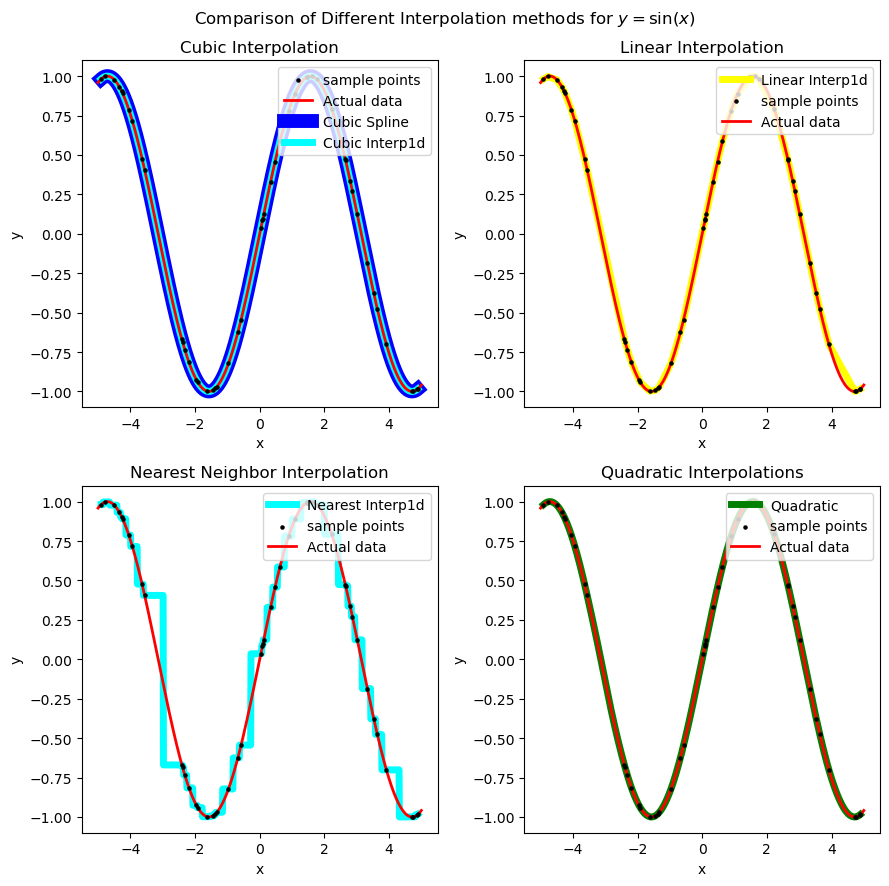

In [5]:
diff_inter_plot (x_sorted, y_sorted, x,f(x), x_new, y_cubicspline, y_interp1d, y_interp1d2, y_interp1d3, y_quadratic, title=r'Comparison of Different Interpolation methods for $y=\sin(x)$')

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [6]:
#importing data set
data = np.loadtxt('dow.txt')
print(data[:5]) #checkingif correct file is imported

[12121.71 12136.44 12226.73 12221.93 12194.13]


### HARDCODED DIFF SAMPLE RATES

In [7]:
#calculates # of data points per sample rate(rounds up to the nearest integer)
samplerate1 = int(np.ceil(len(data)*0.05)) #5% sample rate
samplerate2 = int(np.ceil(len(data)*0.1)) #10% sample rate
samplerate3 = int(np.ceil(len(data)*0.3)) #30% sample rate
samplerate4 = int(np.ceil(len(data)*0.5)) #50% sample rate

#random sample points
indices = np.arange(len(data))
sample_5 = np.random.choice(indices, size = samplerate1, replace = False)
sample_10 = np.random.choice(indices, size = samplerate2, replace = False)
sample_30 = np.random.choice(indices, size = samplerate3, replace = False)
sample_50 = np.random.choice(indices, size =samplerate4, replace = False)

#sorted x values
x_5 = np.sort(sample_5)
x_10 = np.sort(sample_10)
x_30 = np.sort(sample_30)
x_50 = np.sort(sample_50)

#corresponding y vals
sampley_5 = data[x_5]
sampley_10 = data[x_10]
sampley_30 = data[x_30]
sampley_50 = data[x_50]

#interpolated
def linear_interpolate (x,y): #linear interpolation function
    x_new = np.linspace(min(x),max(x), 1000)
    li = interpolate.interp1d(x,y,kind='linear')
    interpolated = li(x_new)
    return x_new, interpolated

#xgrid = grid for plotting
x_grid5, y_5 = linear_interpolate(x_5,sampley_5)
x_grid10, y_10 = linear_interpolate(x_10,sampley_10)
x_grid30, y_30 = linear_interpolate(x_30,sampley_30)
x_grid50, y_50 = linear_interpolate(x_50,sampley_50)

### FOR LOOP OPTIMIZED SAMPLE RATES CODE

In [8]:
import numpy as np
from scipy import interpolate

def generate_samples(data, rates=[0.05, 0.10, 0.30, 0.50]):
    indices = np.arange(len(data)) #row numbers from txt file
    sampling_runs = []
    
    for rate in rates: #calculates random sample points for rates: 5%, 10%, 30%, 50%
        num_samples = int(np.ceil(len(data) * rate))
        x_sample = np.sort(np.random.choice(indices, size=num_samples, replace=False))
        y_sample = data[x_sample]
        x_grid, y_interp = linear_interpolate(x_sample, y_sample)
        
        sampling_runs.append({ #generates list of random x sample points an corresponding y val and x grids for plotting
            'rate': int(rate * 100),
            'x_sample': x_sample,
            'y_sample': y_sample,
            'x_grid': x_grid,
            'y_interp': y_interp
        })
        
    return sampling_runs
sampling_runs = generate_samples(data)

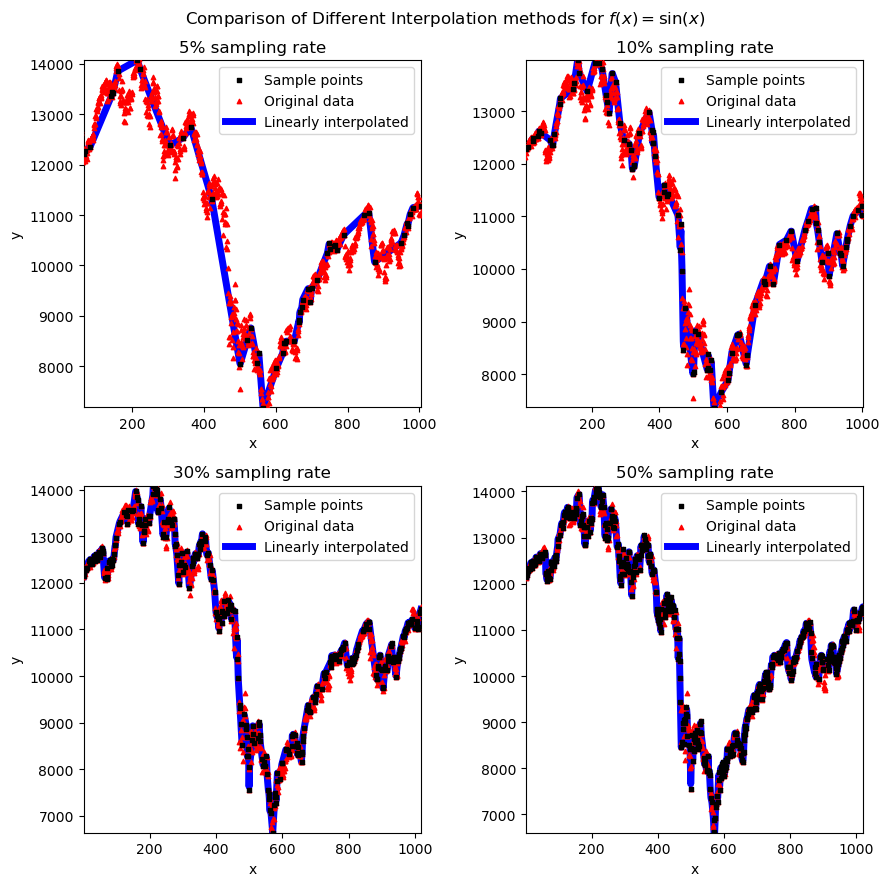

In [9]:
#plotting
def diff_rate_plot(sampling_data, original_x, original_y, main_title=r'Comparison of Different Interpolation methods for $f(x)=\sin(x)$'):
    fig, axs = plt.subplots(2, 2, figsize=(9, 9))
    axs_flat = axs.flatten()
    
    for ax, data in zip(axs_flat, sampling_data):
        #Sample points of diff sample rates
        ax.scatter(data['x_sample'], data['y_sample'], marker='s', color='black', zorder=4, alpha=1, s=5, label='Sample points')
        
        #Original data
        ax.scatter(original_x, original_y, label='Original data', color='red', marker='^', s=10, zorder=3)
        
        #Interpolated curves
        ax.plot(data['x_grid'], data['y_interp'], label='Linearly interpolated', color='blue', lw=5, zorder=2)
        
        ax.set_title(f"{data['rate']}% sampling rate")
        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.legend(loc='upper right')
        ax.set_xlim(min(data['x_sample']), max(data['x_sample']))
        ax.set_ylim(min(data['y_interp']), max(data['y_interp']))
        
    plt.suptitle(main_title)
    plt.tight_layout()
    return fig.show()

diff_rate_plot(sampling_runs, indices, data)

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

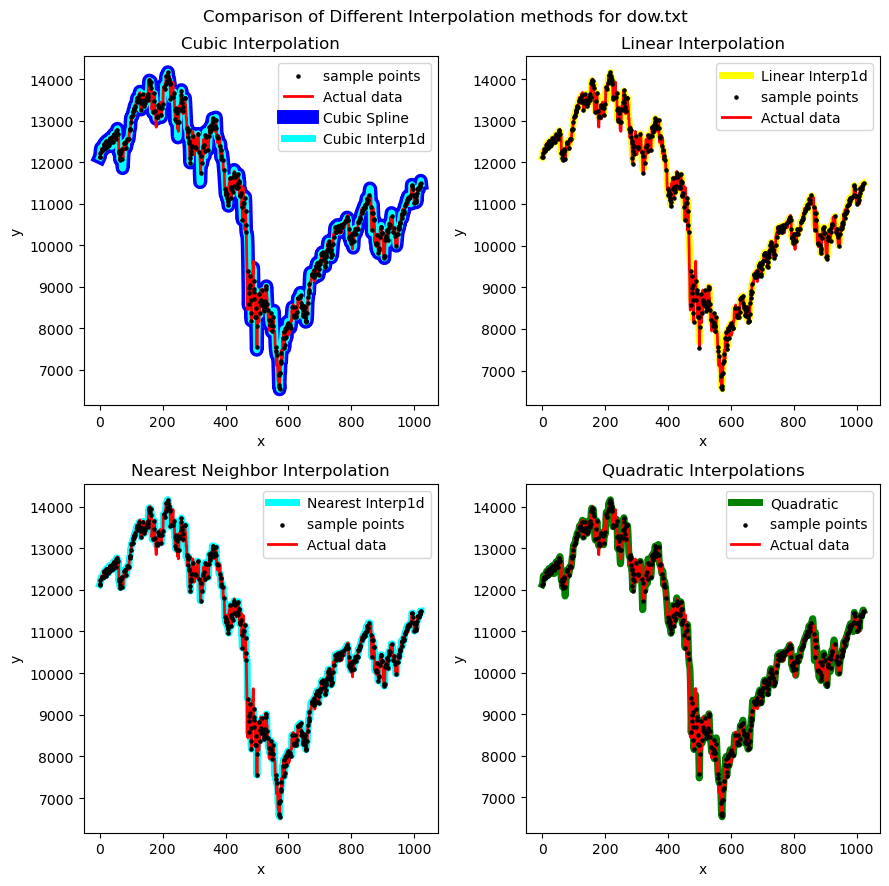

In [10]:
#using 50% sampling rate
#redefining interpolation functions to use x_50 and y_50 as params
cs = interpolate.CubicSpline(x_50,sampley_50) 
cubic_interp1d = interpolate.interp1d(x_50,sampley_50, kind='cubic')
nearest_interp1d = interpolate.interp1d(x_50,sampley_50, kind='nearest')
quadratic_spline = interpolate.make_interp_spline(x_50,sampley_50, k=2)

y_cubicspline = cs(x_grid50)
y_interp1d = cubic_interp1d(x_grid50)
y_interp1d2 = y_50 #reusing linear interpolated from problem 2
y_interp1d3 = nearest_interp1d(x_grid50)
y_quadratic = quadratic_spline(x_grid50)

diff_inter_plot (x_50, sampley_50, indices,data, x_grid50, y_cubicspline, y_interp1d, y_interp1d2, y_interp1d3, y_quadratic, title=r'Comparison of Different Interpolation methods for dow.txt')

### Problem  code summary


The script compares different interpolation methods taken from scipy.interpolate and applies it onto 1D data. It was first applied onto a sine function with randomized sample points to compare interpolation method performance on known function values. Next, it was applied into the real worl data set, dow.txt, to compare different interpolation methods and linear interp1d was applied onto different sampling rates to observe relationship between sampling rate and interpolation accuracy. 

---